# MUSIC Snapshot Budget Experiment

This notebook evaluates 50 NTN UEs per drop using the new shared SectorDrop CDF cache.
All experiment-specific Python code lives in `snapshot_experiments/`.

- **Figure 1:** (a) distinct matched NTN-UE count; (b) path-power-weighted recall and high-INR UE recall.
- **Figure 2:** NTN-UE INR CDF for T = 64, 1024 and 8192, plus one no-nulling baseline.
- **Fixed settings:** 8 GHz UL/DL, lambda = 1e13, 20 frozen scenes, five independent repeats.
- **Snapshot grid:** 64, 128, 256, 512, 1024, 2048, 4096 and 8192.

Run all cells with the **sionna20** kernel. Results are written under `result/MUSIC_SNAPSHOT/`,
parallel to `result/map/` and `result/CDF/`. The 50-UE channels are reused from the new CDF
run; no additional ray tracing is needed here. Raw path precision and recall remain
in the output tables. Snapshot counts do not define physical observation durations.


In [1]:
# Set thread limits before importing NumPy. Restart the kernel before a fresh run.
import os
for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[name] = "1"

from pathlib import Path
from dataclasses import asdict
import json
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "snapshot_experiments").is_dir():
    raise RuntimeError("Start this notebook from the project root directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from snapshot_experiments.config import SnapshotConfig, reference_music_config
from snapshot_experiments.cache import load_inputs
from snapshot_experiments.runner import create_run, run_sweep
from snapshot_experiments.validation import check_observations, validate_noise
from snapshot_experiments.workflow import run_smoke, finalize_run
from snapshot_experiments.analysis import analyze_run
from snapshot_experiments.plotting import plot_results
from snapshot_experiments.storage import atomic_json, run_log
from IPython.display import display, Image, Markdown


## Configuration

Different T values use prefixes of the same waveform/noise stream within each
scene and repeat. The eight budgets share the same RT geometry, TN pairing,
transmit power and UE evaluation mask. Four worker processes each use one BLAS
thread. Set `resume_directory` to an existing result folder to reuse checkpoints;
`None` creates a new run. The optional `MUSIC_SNAPSHOT_RESUME` environment variable
provides the same resume setting for unattended execution.

In [2]:
config = SnapshotConfig(
    source_run="result/CDF/20261026_220019_877592",
    output_root="result/MUSIC_SNAPSHOT",
    num_scenes=20,
    num_ntn_ues=50,
    repeats=5,
    snapshots=(64, 128, 256, 512, 1024, 2048, 4096, 8192),
    cdf_snapshots=(64, 1024, 8192),
    block_size=64,
    frequency_hz=8e9,
    lambda_weight=1e13,
    high_inr_threshold_db=-3.0,
    seed=2026102803,
    workers=4,
    noise_trials=1000,
    bootstrap_draws=2000,
)
music = reference_music_config(config.rank_calibration_file)
resume_directory = os.environ.get("MUSIC_SNAPSHOT_RESUME") or None
run_smoke_check = True
config.validate()
music.validate()
print(json.dumps(asdict(config), indent=2))


{
  "source_run": "result/CDF/20261026_220019_877592",
  "rank_calibration_file": "result/MUSIC_SNAPSHOT/rank_calibration/6e6154c169eb6bf3/calibration.json",
  "output_root": "result/MUSIC_SNAPSHOT",
  "num_scenes": 20,
  "num_ntn_ues": 50,
  "repeats": 5,
  "snapshots": [
    64,
    128,
    256,
    512,
    1024,
    2048,
    4096,
    8192
  ],
  "cdf_snapshots": [
    64,
    1024,
    8192
  ],
  "block_size": 64,
  "frequency_hz": 8000000000.0,
  "lambda_weight": 10000000000000.0,
  "seed": 2026102803,
  "workers": 4,
  "match_angle_deg": 5.0,
  "high_inr_threshold_db": -3.0,
  "channel_epsilon": 1e-12,
  "noise_trials": 1000,
  "noise_wilson_limit": 0.01,
  "bootstrap_draws": 2000,
  "display_floor_db": -120.0,
  "font_directory": "result/CDF/fonts"
}


## Frozen channels and observation checks

The co-frequency cache is selected from `run_config.json`, not from a hard-coded
UL folder index. This cell verifies the no-nulling baseline against the archived
CDF metrics and checks that streamed covariances equal direct X X^H / T.
Truth path matching is used only for offline evaluation.

In [3]:
cases, physical, observation, channel_manifest = load_inputs(config)
result_dir = create_run(config, music, channel_manifest, resume_directory=resume_directory)
checks = check_observations(cases[0], observation)
atomic_json(result_dir / "observation_validation.json", checks)
print(f"Result directory: {result_dir}")
print(f"Frozen scenes: {len(cases)}")
print(f"No-nulling samples: {channel_manifest['baseline_inr_count']} NTN, "
      f"{channel_manifest['baseline_sinr_count']} TN")
print(f"Normalized sensing noise: {observation.sensing_noise_normalized:.6e}")
print(checks)


Reusing 20 legacy RT macros from /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/CDF/20261026_220019_877592/channels; no ray tracing


Result directory: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/MUSIC_SNAPSHOT/20261026_220701_036881
Frozen scenes: 20
No-nulling samples: 918 NTN, 240 TN
Normalized sensing noise: 3.990525e-13
{'prefix_covariance_agrees': True, 'activity_always_one': True, 'shared_user_symbols': True, 'independent_sector_noise': True}


## Independent pure-noise validation

The rank rule was trained on 2,000 independent pure-noise trials at T = 64, before
examining the new channel outcomes. Its frozen rule is `margin(T) = 0.70 * sqrt(64 / T)`.
An independent 1,000-trial validation at each of the eight budgets passed; the original
training and validation records are archived with this run. This notebook additionally
checks the rule using a third noise stream and the actual cached array geometry.

The predefined criterion is a per-sector source-count false-alarm Wilson 95% upper
bound at most 1%. This does not claim a network-wide or signal-present false-alarm rate.


In [4]:
with run_log(result_dir):
    noise_report = validate_noise(result_dir, cases[0], config, music)
print(f"Noise validation passed: {noise_report['passed']}")


Noise T=64: 0/1000, 95% upper=0.0038


Noise T=128: 0/1000, 95% upper=0.0038


Noise T=256: 0/1000, 95% upper=0.0038


Noise T=512: 0/1000, 95% upper=0.0038


Noise T=1024: 0/1000, 95% upper=0.0038


Noise T=2048: 0/1000, 95% upper=0.0038


Noise T=4096: 0/1000, 95% upper=0.0038


Noise T=8192: 0/1000, 95% upper=0.0038


Noise validation passed: True


## Smoke check

A three-scene, two-repeat, three-budget run checks the complete detection,
matching and beamforming path before the full sweep. Its shared-budget results
are compared with the full run after completion to verify prefix invariance.

In [5]:
if run_smoke_check:
    with run_log(result_dir):
        smoke_dir = run_smoke(result_dir, config, music)
    print(f"Smoke check complete: {smoke_dir}")


Reusing 3 legacy RT macros from /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/CDF/20261026_220019_877592/channels; no ray tracing


Snapshot sweep: 3 scenes x 2 repeats x 3 budgets; 0 cached episodes, 4 workers


[  1/6] scene=00, repeat=0, 7.6s, matched UEs at max T=23


[  2/6] scene=01, repeat=0, 8.9s, matched UEs at max T=28


[  3/6] scene=01, repeat=1, 9.3s, matched UEs at max T=28


[  4/6] scene=00, repeat=1, 9.6s, matched UEs at max T=23


[  5/6] scene=02, repeat=0, 5.9s, matched UEs at max T=23


[  6/6] scene=02, repeat=1, 6.1s, matched UEs at max T=24


Smoke check complete: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/MUSIC_SNAPSHOT/20261026_220701_036881/checks/smoke/20261026_220716_962295


## Full finite-snapshot sweep

This cell performs 20 x 5 x 8 = 800 network detections, each containing 12 sectors
and 50 deployed NTN UEs. All UEs remain continuously active. Progress is saved to
`status.json`, `progress/` and `run.log`; completed scene/repeat episodes are atomic
checkpoints. Both lambda values in the source CDF use these same 20 fresh drops.


In [6]:
with run_log(result_dir):
    run_sweep(cases, config, music, physical, observation, result_dir)
print("All planned snapshot evaluations are complete.")


Snapshot sweep: 20 scenes x 5 repeats x 8 budgets; 0 cached episodes, 4 workers


[  1/100] scene=00, repeat=3, 19.4s, matched UEs at max T=23


[  2/100] scene=00, repeat=2, 19.8s, matched UEs at max T=23


[  3/100] scene=00, repeat=0, 19.9s, matched UEs at max T=23


[  4/100] scene=00, repeat=1, 20.7s, matched UEs at max T=23


...

[ 97/100] scene=19, repeat=1, 20.2s, matched UEs at max T=25


[ 98/100] scene=19, repeat=2, 23.3s, matched UEs at max T=28


[ 99/100] scene=19, repeat=3, 22.6s, matched UEs at max T=26


[100/100] scene=19, repeat=4, 20.2s, matched UEs at max T=28


All planned snapshot evaluations are complete.


## Statistics and paper figures

Panel (a) counts distinct UEs with at least one truth-matched direction, deduplicated
across sectors. Panel (b) shows two pooled recall ratios with scene-cluster bootstrap
intervals, preserving all snapshot budgets and waveform/noise repeats within a scene:

- **Path power:** summed power of one-to-one matched rays divided by total valid ray
  power. This excludes coherent cross terms and is not an interference-reduction ratio.
- **High-INR UEs:** matched UEs among the fixed population whose no-nulling network
  INR exceeds -3 dB. A direction match at any sector counts as detection, not as proof
  that the UE is protected. The denominator does not change with T.

No weak paths are removed from the physical channels or INR population. Original
path precision/recall and matched angular errors are saved in the statistics and
results report. The deterministic no-nulling baseline is counted once per scene.
The INR CDF includes the fixed DL-linked population, including undetected UEs and
zero post-nulling INR. Figures use Times New Roman, vector PDF plus 600 dpi PNG,
inside legends, and single-column sizes of 3.5 x 1.9 in and 3.5 x 2.05 in.


In [7]:
with run_log(result_dir):
    detection_rows, nulling_rows = analyze_run(result_dir)
    detection_png, inr_png = plot_results(result_dir)
status = finalize_run(result_dir, config)
print(status)
display(Markdown((result_dir / "RESULTS.md").read_text()))


{'status': 'complete', 'completed_episodes': 100, 'total_episodes': 100, 'completed_network_detections': 800, 'total_network_detections': 800, 'updated': '2026-10-27T02:16:47.798613+00:00'}


# MUSIC snapshot experiment results

20 frozen scenes with 50 NTN UEs each, 5 repeats per scene, 8 GHz UL/DL, lambda=1e+13.

| T | Matched UEs | Power-weighted recall | High-INR UE recall | INR p90 (dB) | INR <= -3 dB | TN SINR p05 (dB) |
|---:|---:|---:|---:|---:|---:|---:|
| 64 | 18.87 | 0.781 | 0.692 | -1.01 | 86.1% | 4.97 |
| 128 | 19.59 | 0.785 | 0.707 | -0.85 | 86.0% | 4.45 |
| 256 | 20.17 | 0.787 | 0.705 | -1.34 | 86.7% | 4.48 |
| 512 | 20.95 | 0.789 | 0.729 | -2.03 | 88.5% | 3.22 |
| 1024 | 21.74 | 0.797 | 0.733 | -3.44 | 90.8% | 1.34 |
| 2048 | 22.73 | 0.796 | 0.739 | -4.04 | 91.5% | 0.73 |
| 4096 | 23.59 | 0.799 | 0.748 | -4.41 | 91.8% | -0.78 |
| 8192 | 24.32 | 0.799 | 0.770 | -5.75 | 93.0% | -1.96 |

Power-weighted recall uses the existing 5-degree one-to-one path matches and sums individual ray powers. It is not the fraction of coherent interference removed.
High-INR UE recall uses the fixed UE set with no-nulling INR > -3 dB; a match at any sector counts once.

Original path metrics remain available for reporting false detections and missed weak paths:

| T | Path precision | Path recall | Matched angular MAE (deg) |
|---:|---:|---:|---:|
| 64 | 0.882 | 0.047 | 1.080 |
| 128 | 0.873 | 0.051 | 1.088 |
| 256 | 0.849 | 0.053 | 1.068 |
| 512 | 0.827 | 0.057 | 1.035 |
| 1024 | 0.811 | 0.060 | 1.033 |
| 2048 | 0.797 | 0.064 | 1.032 |
| 4096 | 0.775 | 0.067 | 0.976 |
| 8192 | 0.764 | 0.071 | 0.992 |

No-nulling baseline: 918 NTN samples and 240 TN samples, each counted once.

The source-count threshold follows a pre-calibrated T-dependent rule. The experiment measures this full detection protocol, not a fixed-threshold covariance-only effect.
Direction matching uses offline truth for evaluation only; it does not decode UE identities or feed truth into beamforming.
The source's normalized sensing noise is preserved. These results must not be relabeled as a 23 dBm uplink experiment.


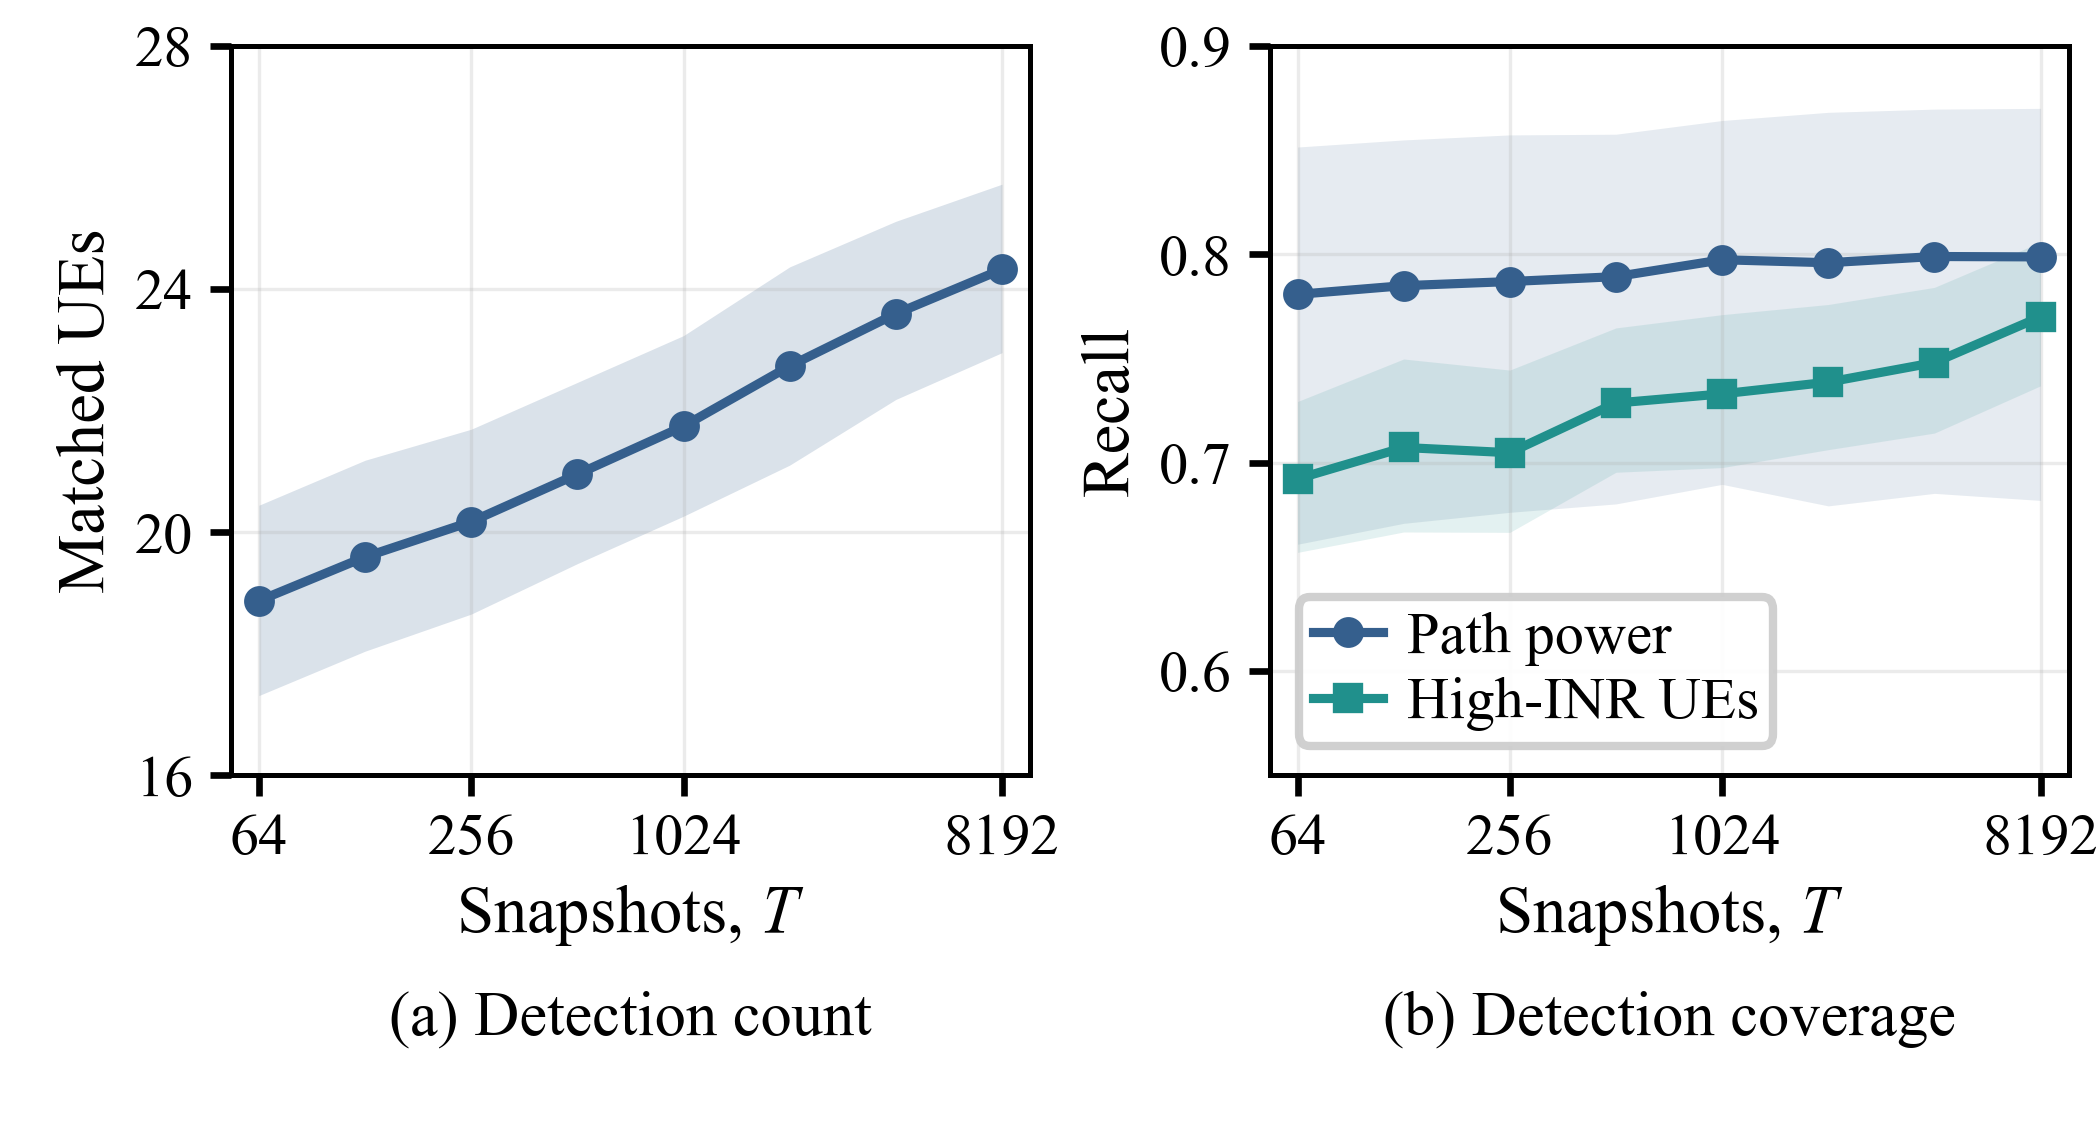

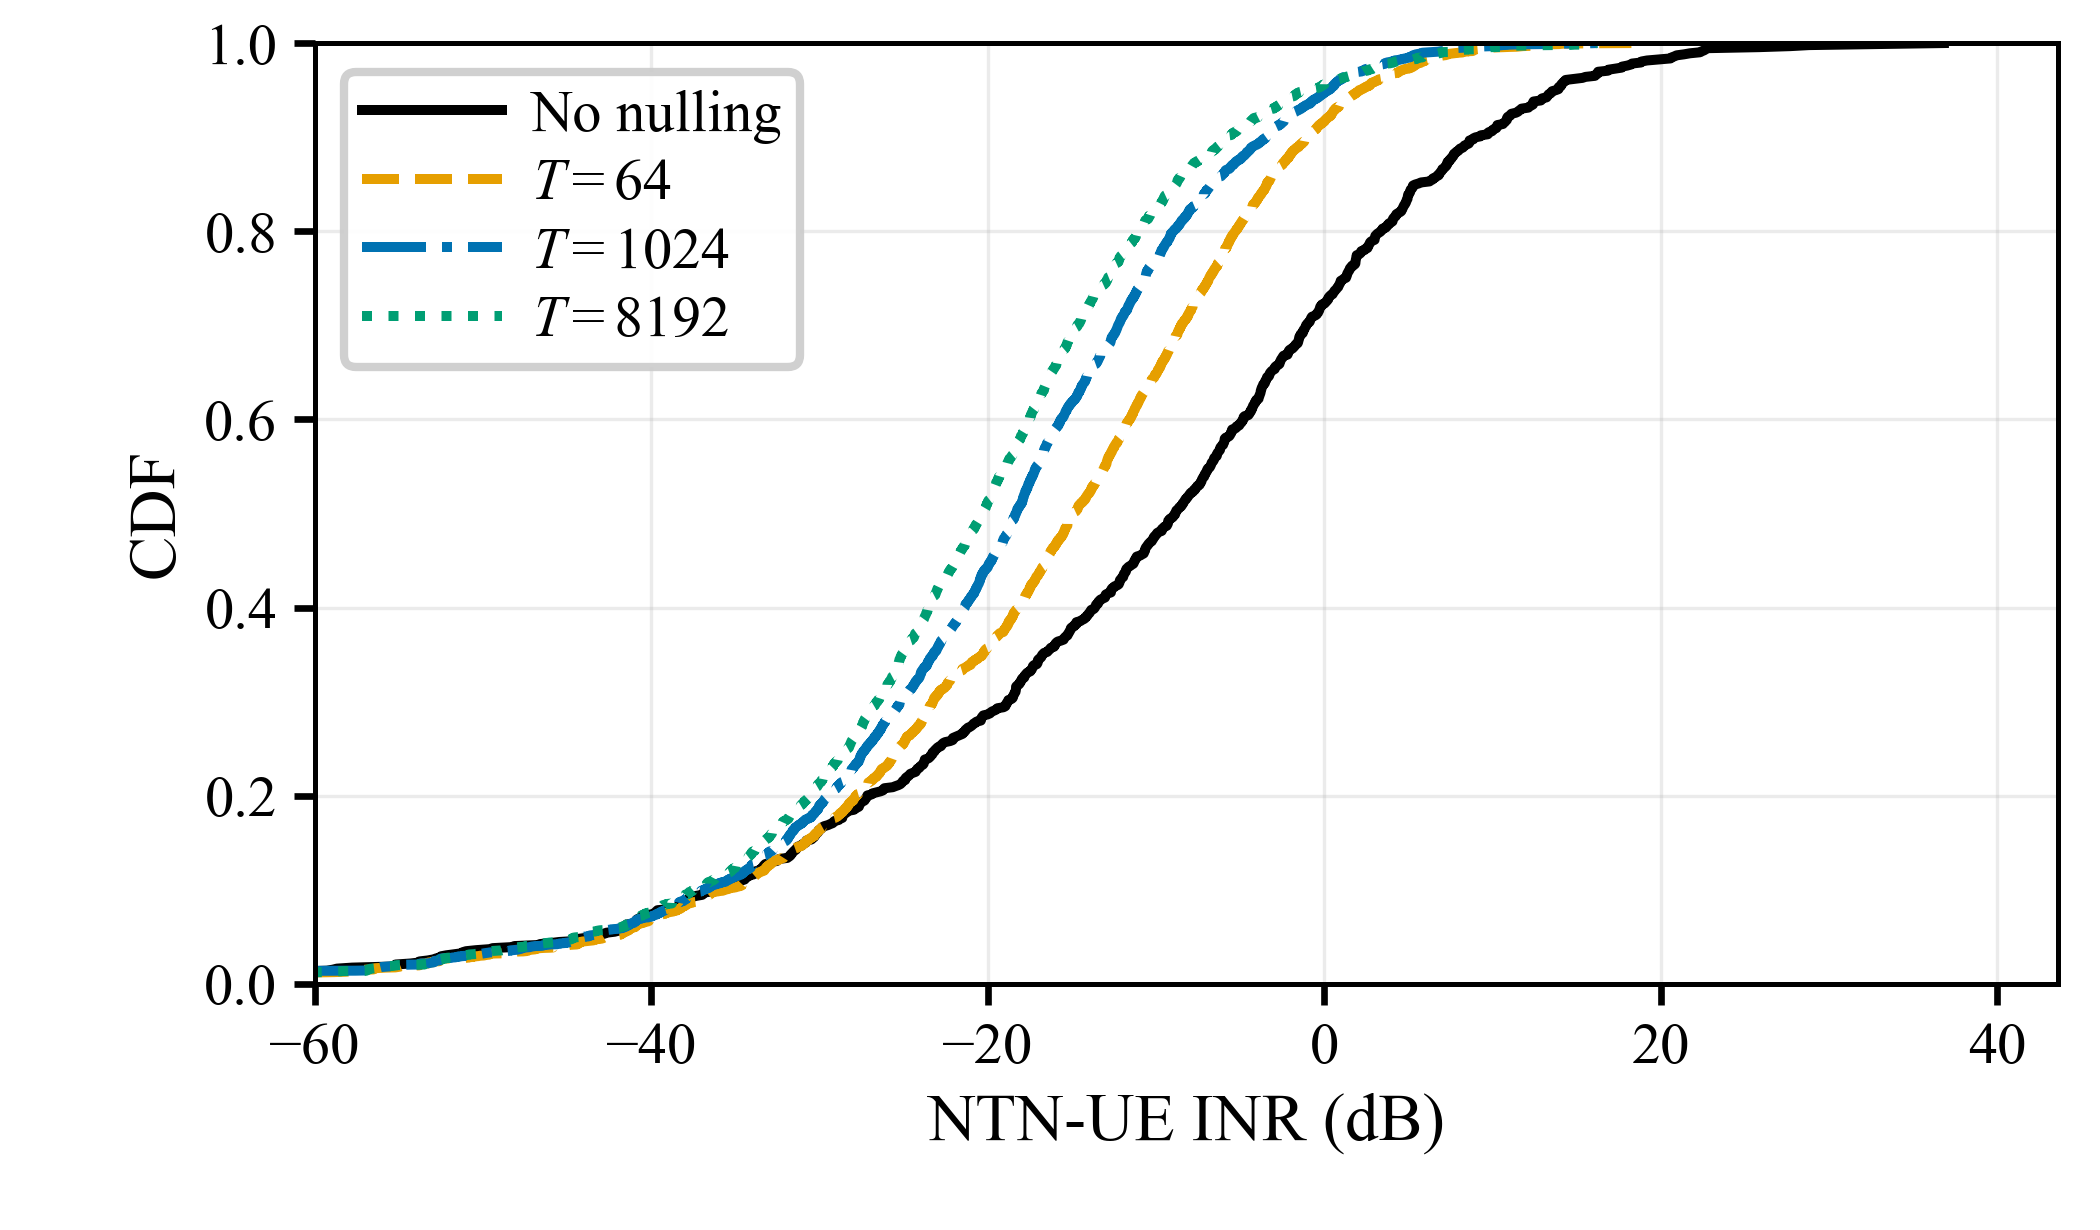

Detection PDF: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/MUSIC_SNAPSHOT/20261026_220701_036881/snapshot_detection_ab.pdf
INR PDF: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/MUSIC_SNAPSHOT/20261026_220701_036881/snapshot_inr_cdf.pdf
RESULT_DIR=/home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/MUSIC_SNAPSHOT/20261026_220701_036881


In [8]:
display(Image(filename=str(detection_png), width=700))
display(Image(filename=str(inr_png), width=700))
print(f"Detection PDF: {result_dir / 'snapshot_detection_ab.pdf'}")
print(f"INR PDF: {result_dir / 'snapshot_inr_cdf.pdf'}")
print(f"RESULT_DIR={result_dir}")
